# ECX-Intelligence: quick EDA notebook
A short, runnable walk through the main findings using `data/processed/orders_with_history.parquet` (delivered Olist orders). The full analysis lives in `research/` and `docs/PROJECT_REPORT.md`. Run it from the `notebooks/` folder or the project root.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
p=Path('../data/processed/orders_with_history.parquet')
if not p.exists(): p=Path('data/processed/orders_with_history.parquet')
df=pd.read_parquet(p)
df=df[df.review_score.notna()].copy()
print(df.shape)
df[['order_purchase_timestamp','review_score','is_late','delay_days','dissatisfied']].head()

(95446, 76)


,order_purchase_timestamp,review_score,is_late,delay_days,dissatisfied
0,2016-09-15 12:16:38,1.0,1.0,36.0,1.0
1,2016-10-03 16:56:50,4.0,0.0,-11.0,0.0
2,2016-10-03 21:13:36,3.0,0.0,-26.0,0.0
3,2016-10-03 22:06:03,1.0,0.0,-23.0,1.0
4,2016-10-03 22:31:31,5.0,0.0,-40.0,0.0


## 1. How are customers rating us?

review_score
1.0    0.098
2.0    0.031
3.0    0.083
4.0    0.197
5.0    0.592
Name: proportion, dtype: float64


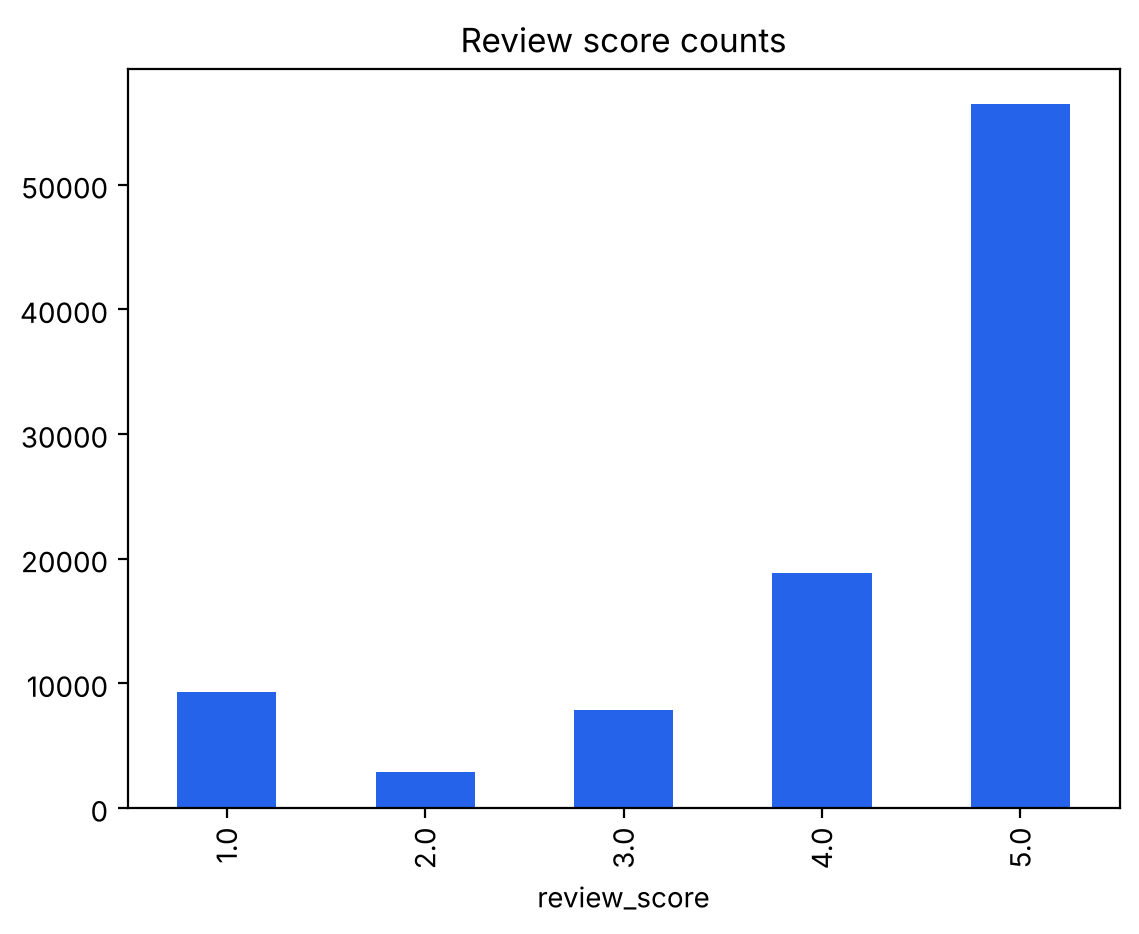

In [2]:
print(df.review_score.value_counts(normalize=True).sort_index().round(3))
df.review_score.value_counts().sort_index().plot.bar(color='#2563eb',title='Review score counts');plt.show()

## 2. Late delivery vs unhappy customers
The key finding: customers whose parcel arrived after the promised date are much more likely to give 1-2 stars. This is an association, not proof of cause.

         orders  mean_score  dissatisfied
on time   89085       4.289         0.093
late       6361       2.271         0.624


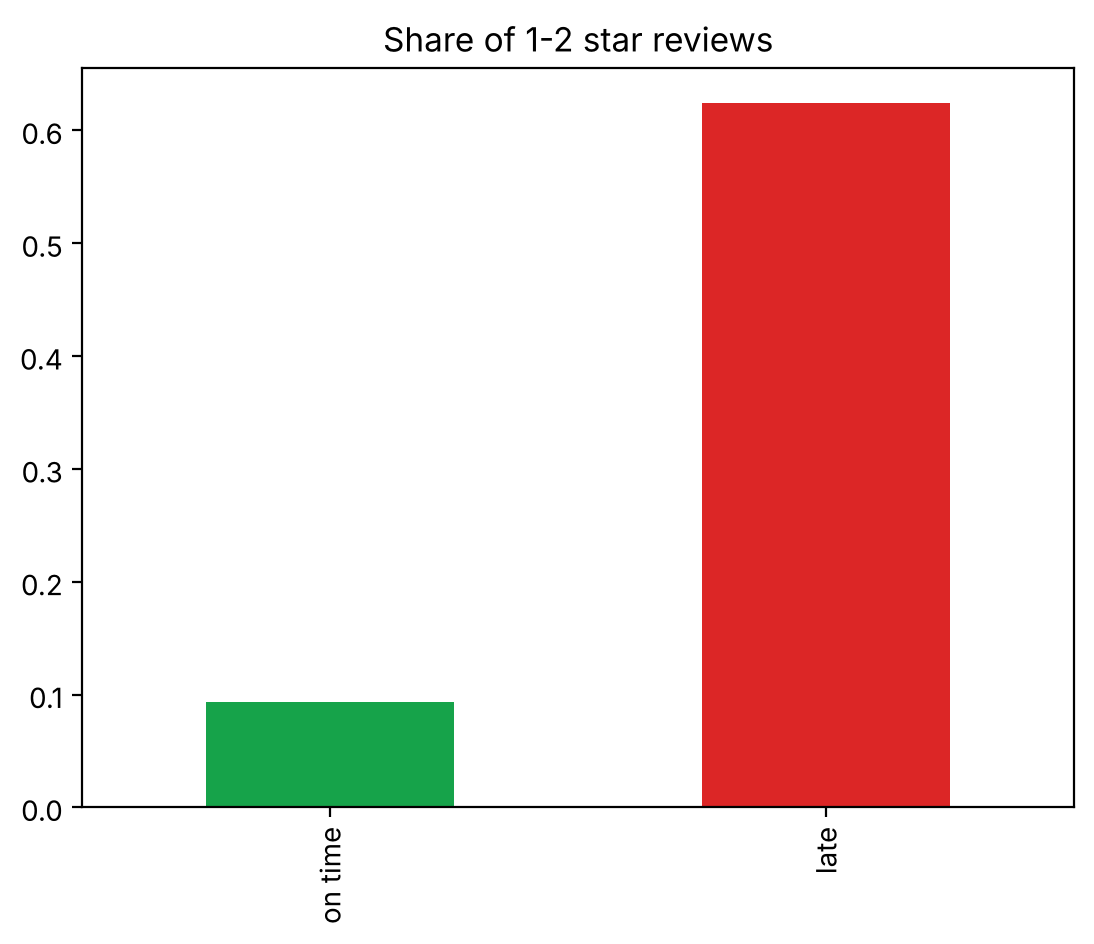

In [3]:
t=df.groupby('is_late').agg(orders=('order_id','count'),mean_score=('review_score','mean'),dissatisfied=('dissatisfied','mean')).round(3)
t.index=['on time','late']
print(t)
t['dissatisfied'].plot.bar(color=['#16a34a','#dc2626'],title='Share of 1-2 star reviews');plt.show()

## 3. How late is too late?

             mean  count
delay_days              
early       0.092  87803
on day      0.125   1277
1-3 late    0.321   1848
4-7 late    0.677   1742
8-14 late   0.802   1442
15+ late    0.783   1329


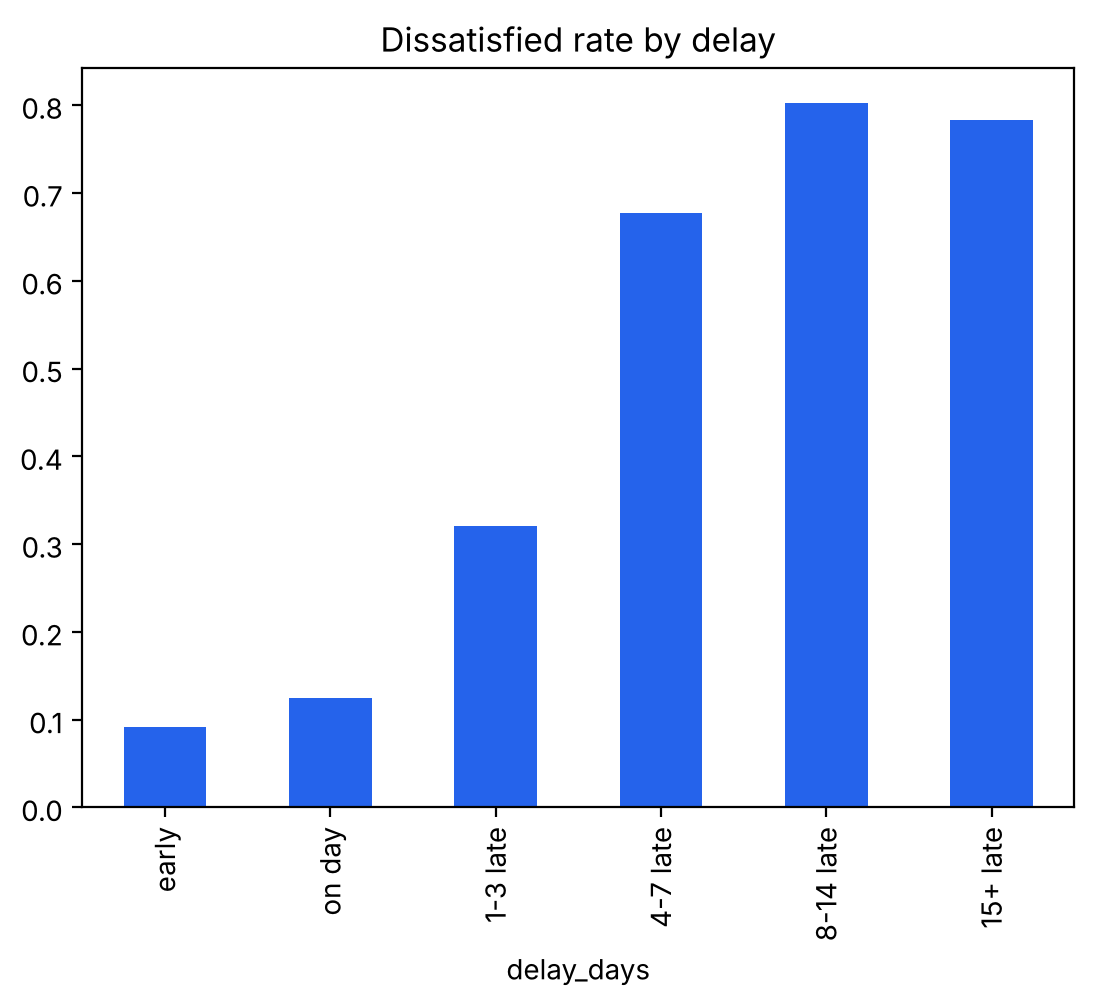

In [4]:
b=pd.cut(df.delay_days,[-100,-1,0,3,7,14,300],labels=['early','on day','1-3 late','4-7 late','8-14 late','15+ late'])
r=df.groupby(b,observed=True).dissatisfied.agg(['mean','count']).round(3);print(r)
r['mean'].plot.bar(color='#2563eb',title='Dissatisfied rate by delay');plt.show()

## 4. Weak sellers and regions (needs enough orders to be fair)

In [5]:
s=df.groupby('primary_seller_id').agg(orders=('order_id','count'),bad=('dissatisfied','mean'));s=s[s.orders>=50].sort_values('bad',ascending=False)
print(len(s),'sellers with >=50 orders; worst 5:');print(s.head(5).round(3))
st=df.groupby('customer_state').agg(orders=('order_id','count'),late=('is_late','mean'),bad=('dissatisfied','mean'));print(st[st.orders>=100].sort_values('late',ascending=False).head(6).round(3))

411 sellers with >=50 orders; worst 5:
                                  orders    bad
primary_seller_id                              
1ca7077d890b907f89be8c954a02686a     107  0.598
2eb70248d66e0e3ef83659f71b244378     182  0.478
972d0f9cf61b499a4812cf0bfa3ad3c4      74  0.405
54965bbe3e4f07ae045b90b0b8541f52      67  0.403
a49928bcdf77c55c6d6e05e09a9b4ca5      94  0.394
                orders   late    bad
customer_state                      
AL                 393  0.209  0.214
MA                 711  0.172  0.200
SE                 332  0.151  0.190
PI                 469  0.139  0.162
CE                1269  0.137  0.172
RJ               12162  0.119  0.183


## 5. Orders with several items


In [6]:
print(df.assign(multi=df.n_items>1).groupby('multi').dissatisfied.mean().round(3))

multi
False    0.113
True     0.268
Name: dissatisfied, dtype: float64


## Reading the results
- Late delivery is the strongest operational signal.
- Seller and state quality differ; check the sample size before judging.
- See `docs/PROJECT_REPORT.md` for tests, effect sizes, models and limits.